# Regularized logistic regression (Esther)

## 0. Importations

In [1]:
from helpers import *
from implementations import *
from preprocessing import *
from validation import *
import numpy as np
from pathlib import Path
from plots import *

## 1. Data loading & preprocessing

In [6]:
project_dir = Path.cwd()  # Updated to use Path.cwd()
data_dir = project_dir / "data" / "dataset"
output_dir = project_dir / "outputs"
output_dir.mkdir(exist_ok=True)

x_train, x_test, y_train, _, test_ids = load_csv_data(data_dir)
names = load_feature_names(data_dir)

In [7]:
tx_train, tx_test = clean_and_standardize(x_train, x_test, names)
y01 = (y_train == 1).astype(float)   # {-1,1} -> {0,1} pour la régression logistique

## 2. Split train & validation set

In [8]:
tx_tr, tx_va, y_tr, y_va = split_train_validation(y_train, tx_train)   # labels en {-1, 1}
y_tr01 = (y_tr == 1).astype(float) 

## 3. First training (verify the loss decrease)

In [9]:
max_iters, gamma = 500, 0.5
w0 = np.zeros(tx_train.shape[1])

w, loss = reg_logistic_regression(y_tr01, tx_tr, 1e-4, w0, max_iters, gamma)
print("loss train :", loss, "| loss validation :", logistic_loss((y_va == 1).astype(float), tx_va, w))

scores = tx_va @ w
t = best_threshold(y_va, scores)
f1 = f1_score(y_va, np.where(scores >= t, 1, -1))
print(f"F1 validation = {f1:.3f} (seuil {t:.2f})")

loss train : 0.22663116131505262 | loss validation : 0.22765180504795568
F1 validation = 0.416 (seuil -1.38)


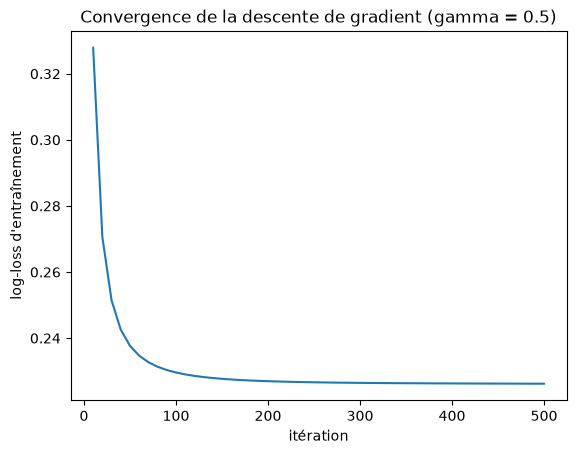

In [10]:
# convergence curve on a 50,000-row subsample (faster, same shape)
plot_convergence(y_tr[:50000], tx_tr[:50000], lambda_=0, gamma=0.5, max_iters=500,
                 path=output_dir / "convergence.png")

## 4. Lambda tuning

4.1 Un seul split : entraînement sur 80 %, validation sur 20 %

In [11]:
'''
results = []
for lambda_ in [0, 1e-5, 1e-4, 1e-3, 1e-2]:
    w, _ = reg_logistic_regression(y_tr01, tx_tr, lambda_, w0, max_iters, gamma)
    scores = tx_va @ w
    t = best_threshold(y_va, scores)
    f1 = f1_score(y_va, np.where(scores >= t, 1, -1))
    results.append((f1, lambda_, t))
    print(f"lambda = {lambda_:g}  ->  F1 = {f1:.3f}  (seuil {t:.2f})")

best_f1, best_lambda, best_t = max(results)
print("meilleur :", best_lambda, best_t, best_f1)
'''

'\nresults = []\nfor lambda_ in [0, 1e-5, 1e-4, 1e-3, 1e-2]:\n    w, _ = reg_logistic_regression(y_tr01, tx_tr, lambda_, w0, max_iters, gamma)\n    scores = tx_va @ w\n    t = best_threshold(y_va, scores)\n    f1 = f1_score(y_va, np.where(scores >= t, 1, -1))\n    results.append((f1, lambda_, t))\n    print(f"lambda = {lambda_:g}  ->  F1 = {f1:.3f}  (seuil {t:.2f})")\n\nbest_f1, best_lambda, best_t = max(results)\nprint("meilleur :", best_lambda, best_t, best_f1)\n'

4.2 Cross validation sur 5 plis

In [12]:
from implementations import reg_logistic_regression  # à mettre en haut du fichier


def build_k_indices(n, k, seed=1):
    """Randomly split the indices 0..n-1 into k folds of (almost) equal size.

    Args:
        n: number of samples
        k: number of folds
        seed: random seed, so that the folds are the same at every run

    Returns:
        a list of k arrays of indices
    """
    rng = np.random.default_rng(seed)
    return np.array_split(rng.permutation(n), k)


def cross_validation(y, tx, lambda_, k=5, max_iters=500, gamma=0.5, seed=1):
    """Evaluate reg_logistic_regression with k-fold cross validation.

    Each fold is used once as validation set while the model is trained on
    the k-1 other folds. On each validation fold, the decision threshold is
    chosen to maximize the F1 score.

    Args:
        y: shape=(N, ), labels in {-1, 1}
        tx: shape=(N, D), cleaned data with the bias column
        lambda_: scalar, the regularization parameter
        k: number of folds
        max_iters: number of iterations of gradient descent
        gamma: step size of gradient descent
        seed: random seed for the folds

    Returns:
        f1s: shape=(k, ), F1 score on each validation fold
        thresholds: shape=(k, ), best threshold on each validation fold
    """
    folds = build_k_indices(len(y), k, seed)
    f1s, thresholds = [], []
    for i in range(k):
        val = folds[i]
        tr = np.concatenate([folds[j] for j in range(k) if j != i])

        # train on the k-1 other folds (labels in {0, 1} for logistic regression)
        w0 = np.zeros(tx.shape[1])
        w, _ = reg_logistic_regression(
            (y[tr] == 1).astype(float), tx[tr], lambda_, w0, max_iters, gamma
        )

        # evaluate on the validation fold
        scores = tx[val] @ w
        t = best_threshold(y[val], scores)
        f1s.append(f1_score(y[val], np.where(scores >= t, 1, -1)))
        thresholds.append(t)
    return np.array(f1s), np.array(thresholds)

In [13]:
results = []
for lambda_ in [0, 1e-5, 1e-4, 1e-3, 1e-2]:
    f1s, ts = cross_validation(y_train, tx_train, lambda_, max_iters=max_iters, gamma=gamma)
    results.append((f1s.mean(), f1s.std(), lambda_, ts.mean()))
    print(f"lambda = {lambda_:g}  ->  F1 = {f1s.mean():.3f} ± {f1s.std():.3f}  (seuil {ts.mean():.2f})")

best_f1, _, best_lambda, best_t = max(results)
print("meilleur :", best_lambda, best_t, best_f1)

lambda = 0  ->  F1 = 0.412 ± 0.004  (seuil -1.39)
lambda = 1e-05  ->  F1 = 0.412 ± 0.004  (seuil -1.41)
lambda = 0.0001  ->  F1 = 0.412 ± 0.004  (seuil -1.40)
lambda = 0.001  ->  F1 = 0.412 ± 0.004  (seuil -1.36)
lambda = 0.01  ->  F1 = 0.409 ± 0.003  (seuil -1.13)
meilleur : 0.0001 -1.3965942794340078 0.41186696778213217


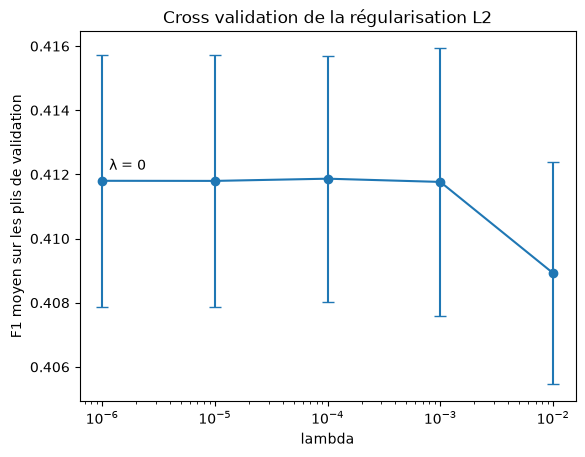

In [14]:
plot_cv_lambda(results, path=output_dir / "cv_lambda.png")

4.3 Analyse du modèle choisi

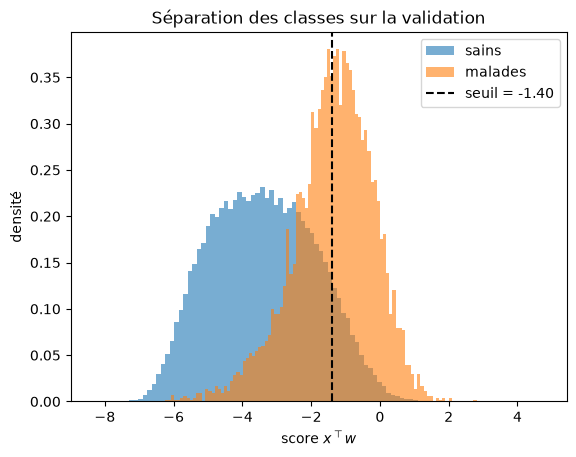

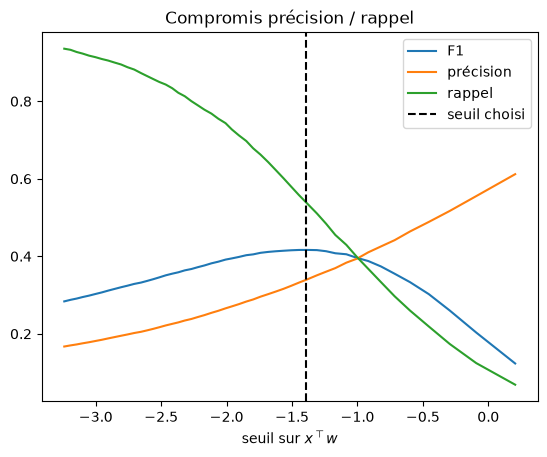

In [15]:
# model trained on the split with the chosen lambda, evaluated on the validation part
w, _ = reg_logistic_regression((y_tr == 1).astype(float), tx_tr, best_lambda,
                               np.zeros(tx_tr.shape[1]), 500, 0.5)
scores = tx_va @ w

plot_score_distribution(y_va, scores, best_t, path=output_dir / "scores.png")
plot_threshold_curves(y_va, scores, best_t, path=output_dir / "threshold.png")

Les scores des deux classes sont décalés mais se chevauchent largement, ce qui limite la performance atteignable par un classifieur linéaire. Le seuil qui maximise le F1 (−1.6, soit une probabilité ≈ 0.17) donne un rappel de 0.60 pour une précision de 0.31; le maximum du F1 étant plat, ce choix est peu sensible à la valeur exacte du seuil.

## 5. Final training & Submission

In [19]:
w, loss = reg_logistic_regression(y01, tx_train, best_lambda, w0, max_iters, gamma)
print("loss train :", loss, "| loss validation :", logistic_loss((y_va == 1).astype(float), tx_va, w))

scores = tx_va @ w
t = best_threshold(y_va, scores)
f1 = f1_score(y_va, np.where(scores >= t, 1, -1))
print(f"F1 validation = {f1:.3f} (seuil {t:.2f})")

loss train : 0.22677335399481877 | loss validation : 0.22718003002739195
F1 validation = 0.417 (seuil -1.38)


Résultats: 

4.1 loss train : 0.22771585642698902 | loss validation : 0.22819828457209074 
      
            F1 validation = 0.418 (seuil -1.46)

4.2 loss train : 0.23188015843203327 | loss validation : 0.23239870804220816
      
            F1 validation = 0.404 (seuil -1.52)

In [20]:
y_pred = np.where(tx_test @ w >= best_t, 1, -1)
create_csv_submission(test_ids, y_pred, output_dir / "submission_reg_logistic.csv")
print("prédits positifs :", (y_pred == 1).mean())

prédits positifs : 0.14142568500351987


In [21]:
sub = np.genfromtxt(output_dir / "submission_reg_logistic.csv", delimiter=",", names=True)
print(open(output_dir / "submission_reg_logistic.csv").readlines()[:3])

['Id,Prediction\n', '328135,-1\n', '328136,-1\n']


We then finally send the submission_reg_logistic.csv to the platform contest and also as final submission for this project. 